# SupeRR Selector — Pressure Modelling & XGBoost Comparison

**Research objective:** compare a transparent, manually weighted chase Pressure Index (PI) with an XGBoost classifier trained on synthetic pressure classes, then inspect how each behaves on the supplied IPL/T20I ball-by-ball data.

> **Critical distinction:** the XGBoost model is trained on a synthetic teacher rule created by us. Synthetic holdout scores tell us how well XGBoost learns that rule. They do **not** establish that its scores represent true psychological pressure. Applying this model to historical data compares two scoring systems; it does not provide an independent ground-truth validation.

The notebook writes processed CSVs, a model, metrics and reproducible graphs into the project folders.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: /mnt/data/cricket-analysis


## 1. Run the complete pipeline

This step loads all six source tables, reconstructs pre-delivery states, calculates the PI, generates synthetic labelled scenarios, trains XGBoost, applies the classifier to historical chase states, and writes diagnostics/exports. It may take a short while because the model is trained from scratch.

In [2]:
from cricket_pressure.analysis import run_analysis

results = run_analysis(ROOT, n_synthetic=40000, seed=42)
summary = results["summary"]
display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))

/mnt/data/cricket-analysis/cricket_pressure/features.py:116: RuntimeWarning: 3,166 bye/legbye deliveries have unresolved run values. Treat reconstructed scores and downstream PI/XGBoost comparisons as provisional until scorecards are reconciled.
  warnings.warn(


{
  "selected_matches": 837,
  "selected_deliveries_innings_1_2": 193988,
  "chase_pressure_deliveries": 91419,
  "chase_matches": 815,
  "unresolved_bye_legbye_deliveries": 3166,
  "synthetic_accuracy": 0.9326136363636364,
  "synthetic_macro_f1": 0.8874825678175944,
  "real_pi_xgb_spearman": 0.991741463846223,
  "real_pi_xgb_pearson": 0.9419816951933444,
  "mean_pi": 41.951448030948534,
  "mean_xgb_synthetic_score": 37.552178693458394
}


,value
selected_matches,837.000000
selected_deliveries_innings_1_2,193988.000000
chase_pressure_deliveries,91419.000000
chase_matches,815.000000
unresolved_bye_legbye_deliveries,3166.000000
synthetic_accuracy,0.932614
synthetic_macro_f1,0.887483
real_pi_xgb_spearman,0.991741
real_pi_xgb_pearson,0.941982
mean_pi,41.951448


## 2. PI-only baseline

The first score is deliberately transparent and hand-weighted. All components are normalized to 0–1 before combining them:

| Component | Weight | Interpretation |
|---|---:|---|
| Required run rate | 25.0% | Higher required rate increases chase pressure |
| Wickets lost | 20.0% | Fewer wickets remaining increases pressure |
| Innings time urgency | 15.0% | More of the scheduled innings consumed increases urgency |
| Momentum shortfall | 15.0% | Required rate above recent scoring rate increases pressure |
| Death-over pressure | 10.0% | Additional urgency in the final 30 legal balls |
| Target difficulty | 7.5% | First-innings score percentile in the same format/season |
| Match stakes | 7.5% | Stage/knockout proxy from match metadata |

\[PI = 100\sum_j w_j x_j\]

The death-over component is related to time urgency, so it may double-count part of the same effect. We explicitly inspect sensitivity to that choice below. The `must_win` flag cannot be reliably inferred because tournament standings and points tables are absent.

In [3]:
real = results["real"].copy()
print(f"Historical chase states: {len(real):,} across {real.match_id.nunique():,} matches")
display(real[["pressure_index", "pressure_category"]].describe(include="all"))
display(real["pressure_category"].value_counts(dropna=False).to_frame("deliveries"))

Historical chase states: 91,419 across 815 matches


,pressure_index,pressure_category
count,91419.000000,91419
unique,NaN,4
top,NaN,Moderate
freq,NaN,53577
mean,41.951448,NaN
std,16.925635,NaN
min,4.415747,NaN
25%,29.510075,NaN
50%,38.887119,NaN
75%,51.774195,NaN


,deliveries
pressure_category,
Moderate,53577
Low,24027
High,10722
Extreme,3093


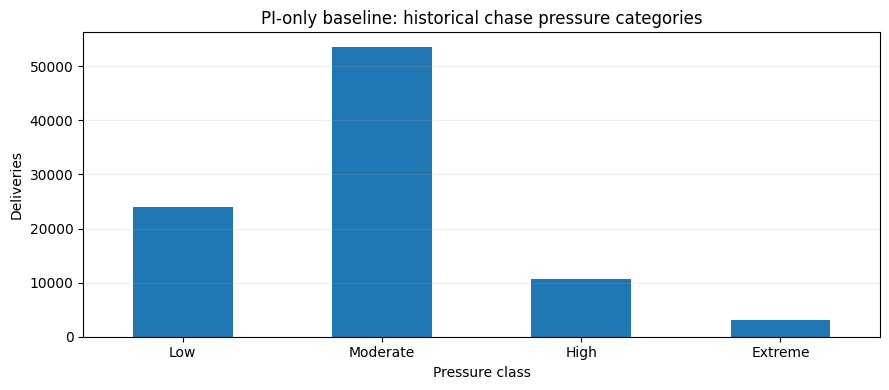

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
real["pressure_category"].astype(str).value_counts().reindex(["Low", "Moderate", "High", "Extreme"]).plot(kind="bar", ax=ax)
ax.set(title="PI-only baseline: historical chase pressure categories", xlabel="Pressure class", ylabel="Deliveries")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=.2)
plt.tight_layout(); plt.show()

## 3. Synthetic scenario generation

The generator samples plausible T20 chase situations: required run rate, wickets remaining, balls remaining, recent run rate, target difficulty, match stakes and format. It then applies a transparent nonlinear teacher formula with interactions and small random noise, creating Low / Moderate / High / Extreme labels.

This gives us a controlled supervised-learning exercise. The labels are **not** expert annotations or historical outcomes; the model is learning the synthetic definition we authored.

In [5]:
synthetic = results["synthetic"]
synthetic_test = results["synthetic_test"]
metrics = results["synthetic_metrics"]
print("Synthetic training dataset:", synthetic.shape)
display(synthetic["synthetic_pressure_class"].value_counts().reindex(["Low", "Moderate", "High", "Extreme"]).to_frame("count"))
display(pd.DataFrame({k: [v] for k, v in metrics.items() if isinstance(v, (int, float))}).T.rename(columns={0:"value"}))

Synthetic training dataset: (40000, 12)


,count
synthetic_pressure_class,
Low,6076
Moderate,26837
High,6409
Extreme,678


,value
accuracy,0.932614
macro_f1,0.887483
teacher_score_mae_vs_class_midpoint,5.169248
teacher_score_r2_vs_class_midpoint,0.835138
n_train,31200.000000
n_test,8800.000000


## 4. XGBoost holdout diagnostics

The test split is stratified and held out from model fitting. Accuracy and macro-F1 measure synthetic class agreement. The expected score is calculated from class probabilities and fixed class midpoints (15, 45, 70, 90). These are synthetic-task metrics only.

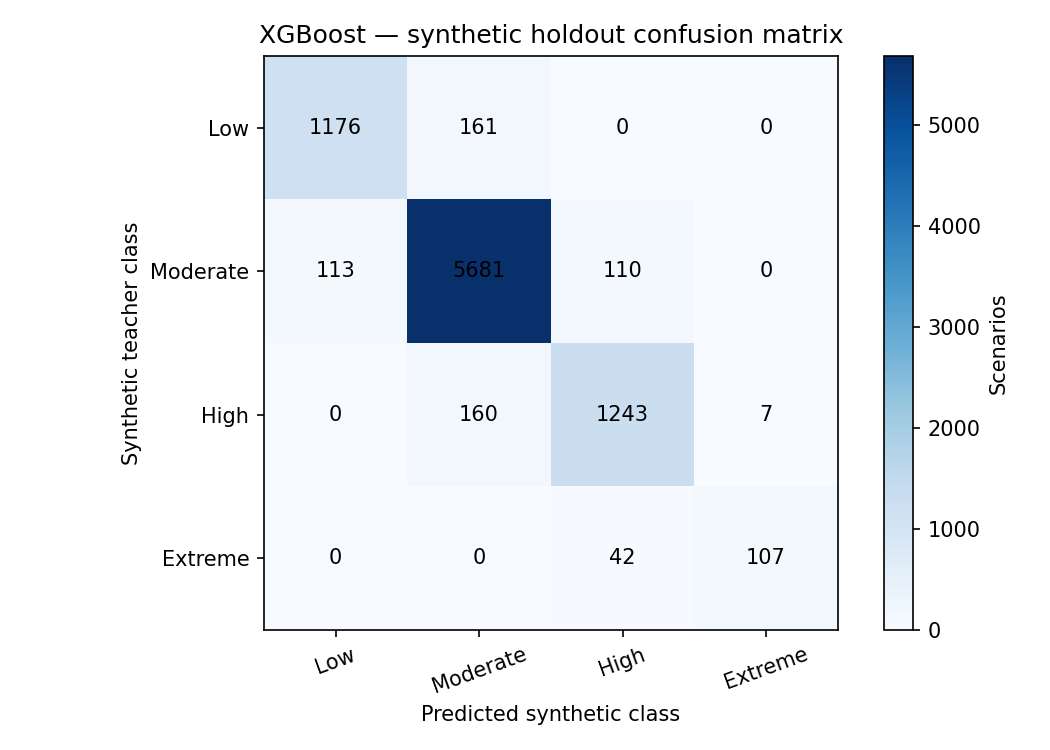

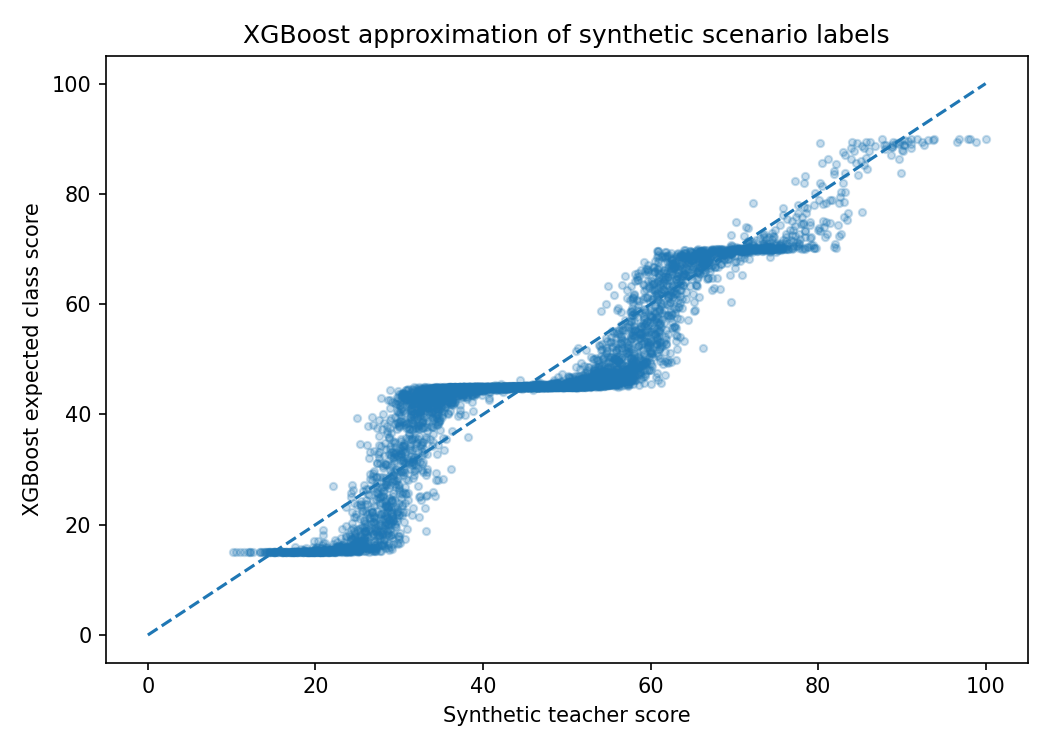

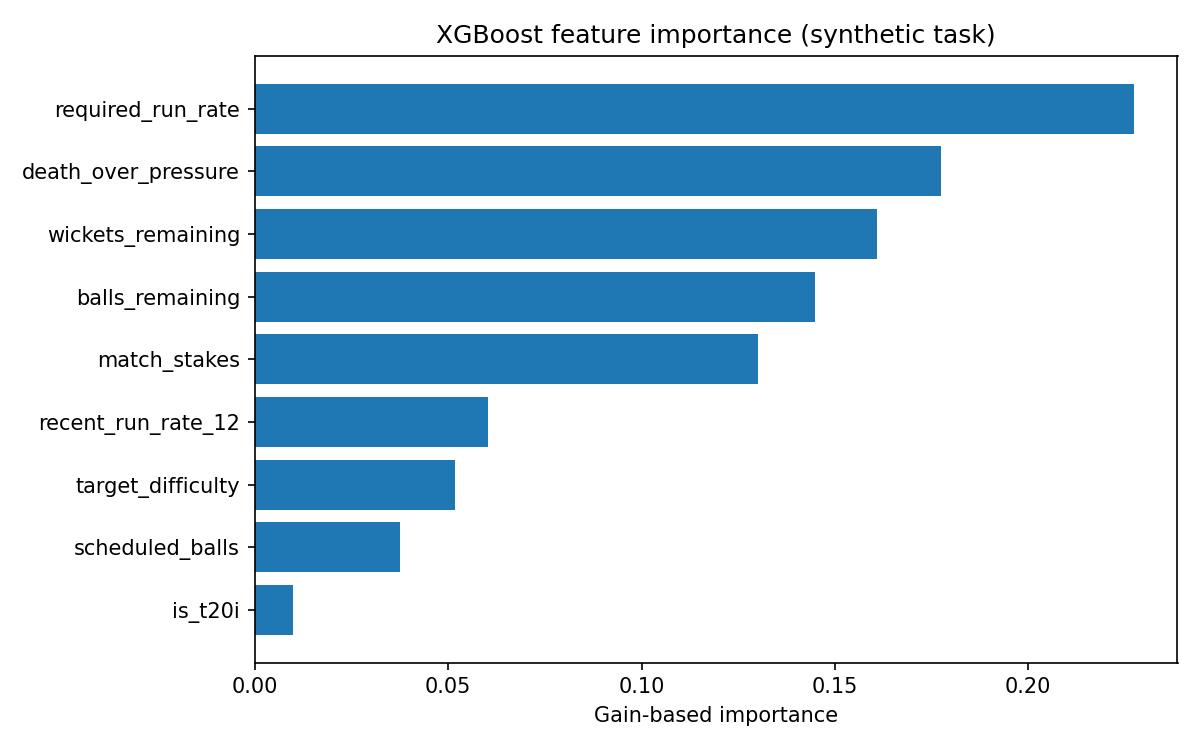

,feature,importance
0,required_run_rate,0.227219
7,death_over_pressure,0.177532
1,wickets_remaining,0.160879
2,balls_remaining,0.144928
6,match_stakes,0.130020
4,recent_run_rate_12,0.060286
5,target_difficulty,0.051808
3,scheduled_balls,0.037500
8,is_t20i,0.009826


In [6]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "synthetic_confusion_matrix.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "synthetic_score_fit.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "xgb_feature_importance.png")))
display(results["importance"])

## 5. Apply synthetic-trained XGBoost to historical match states

The classifier receives the same kinds of state variables for real chases. We compare its expected class score with the hand-weighted PI. A high correlation means the two scoring systems rank these states similarly; it is **not** evidence that either score is objectively correct.

In [7]:
comparison_stats = pd.DataFrame({
    "metric": ["Pearson correlation", "Spearman rank correlation", "Mean absolute score difference", "Mean PI", "Mean XGBoost score"],
    "value": [
        real[["pressure_index", "xgb_pressure_score"]].corr().iloc[0,1],
        real[["pressure_index", "xgb_pressure_score"]].corr(method="spearman").iloc[0,1],
        (real["pressure_index"] - real["xgb_pressure_score"]).abs().mean(),
        real["pressure_index"].mean(),
        real["xgb_pressure_score"].mean(),
    ]
})
display(comparison_stats)
display(results["class_comparison"])

,metric,value
0,Pearson correlation,0.941982
1,Spearman rank correlation,0.991741
2,Mean absolute score difference,6.291957
3,Mean PI,41.951448
4,Mean XGBoost score,37.552179


xgb_pressure_class,Extreme,High,Low,Moderate
pressure_category,,,,
Low,0,0,23975,52
Moderate,0,6,9157,44414
High,33,7180,0,3509
Extreme,2417,676,0,0


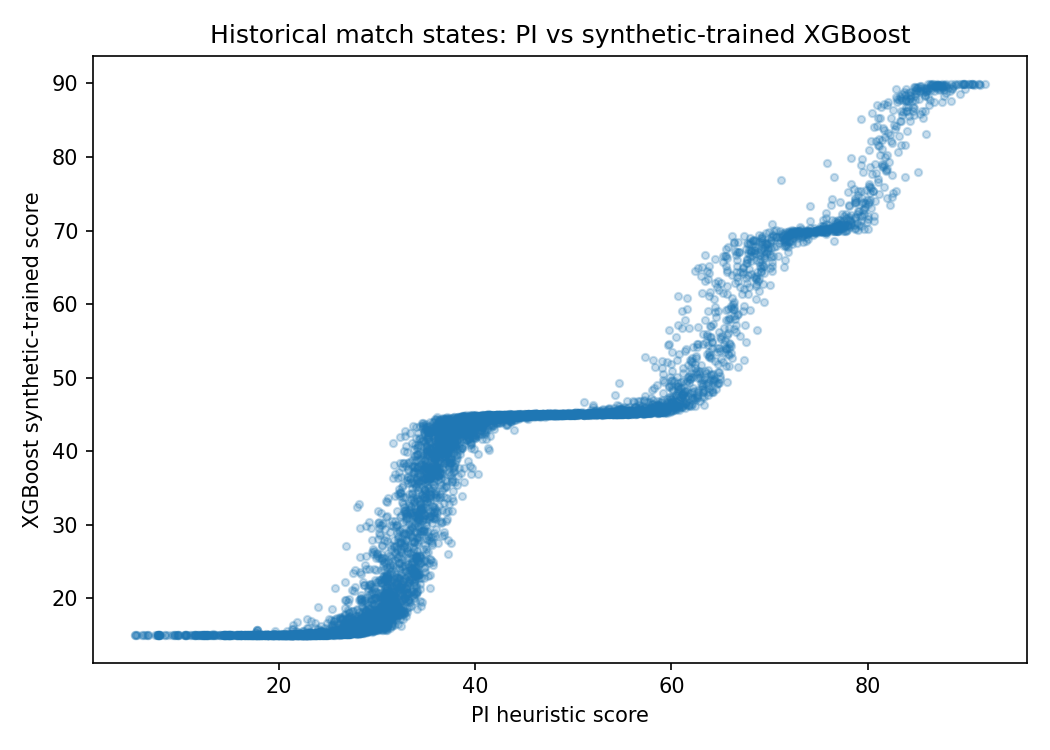

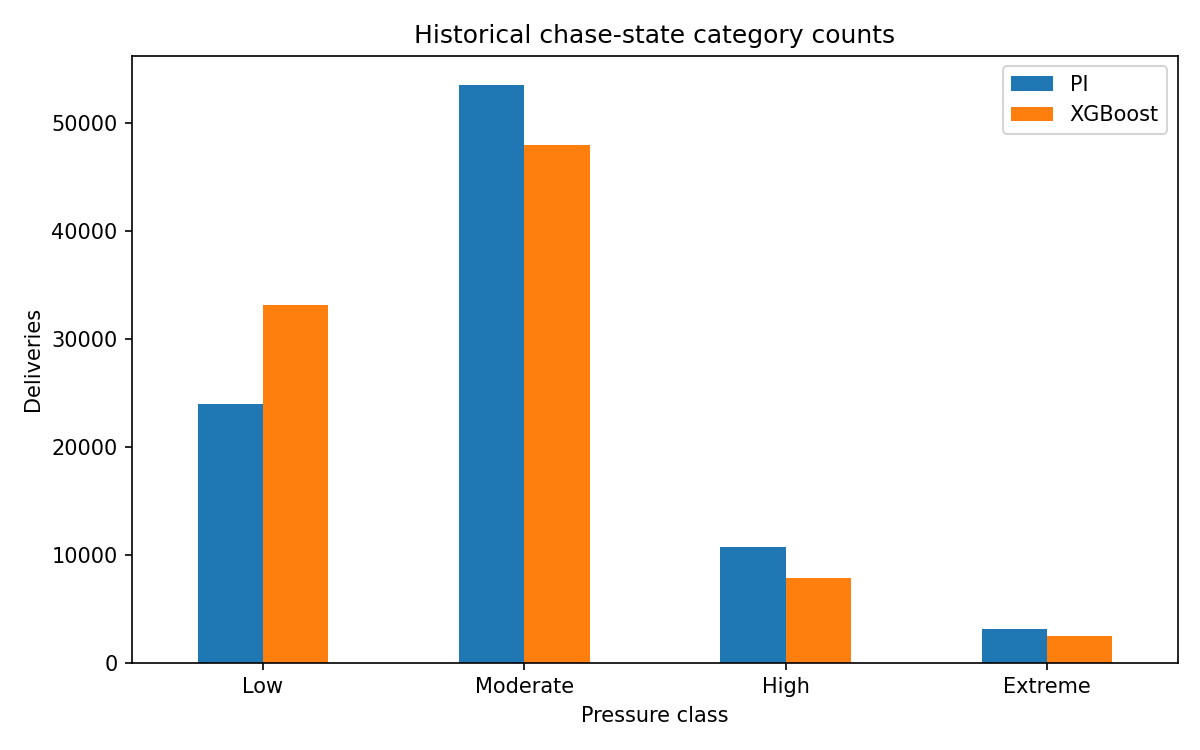

In [8]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "pi_vs_xgb_scatter.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "pi_vs_xgb_class_counts.png")))

## 6. Weight sensitivity

We compare the baseline with RRR-heavy, momentum-heavy and stakes-heavy weight configurations. Spearman correlation measures whether the relative ordering of delivery-level pressure scores changes. This is a robustness check, not a way to discover the true weights.

,scenario,mean_score,median_score,spearman_vs_baseline
0,baseline,41.951448,38.887119,1.000000
1,rrr_situation_heavy,46.984169,44.643315,0.994326
2,momentum_heavy,39.080888,35.594267,0.989416
3,stakes_heavy,40.958661,38.936136,0.987321


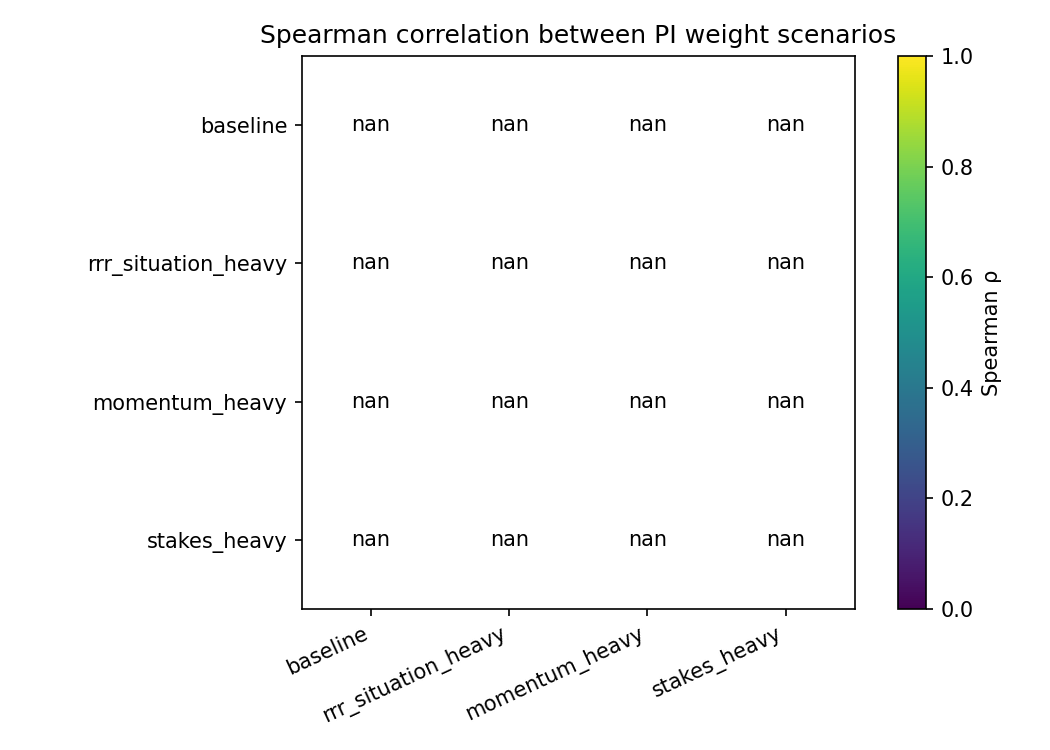

In [9]:
sensitivity = results["sensitivity"]
display(sensitivity)
display(Image(filename=str(ROOT / "outputs" / "figures" / "weight_sensitivity_heatmap.png")))

## 7. Hand-picked scenario stress test

These scenarios are controlled illustrations rather than observed scorecards. They help check whether directionality is sensible: higher RRR, fewer wickets, fewer balls, poor momentum, a high relative target, or higher match stakes should generally increase the relevant pressure components.

,scenario,required_run_rate,wickets_remaining,balls_remaining,target_difficulty,match_stakes,pressure_index,xgb_pressure_score,xgb_pressure_class
0,"Early, comfortable chase",6.5,9,102,0.35,0.25,22.29,15.05,Low
1,"Early, high required rate",14.0,9,102,0.85,0.25,45.00,44.97,Moderate
2,"Death overs, manageable chase",8.0,6,18,0.55,0.25,47.42,44.97,Moderate
3,"Death overs, high required rate",17.0,5,18,0.90,0.25,70.38,68.93,High
4,"Death overs, only two wickets",13.0,2,12,0.75,0.25,74.25,69.41,High
5,"High target, early overs",10.0,9,96,0.98,0.25,36.31,35.50,Moderate
6,"Knockout, otherwise moderate chase",9.0,7,48,0.55,0.95,45.62,44.99,Moderate
7,"Short-format chase, tight finish",12.0,4,12,0.80,0.90,70.25,69.06,High


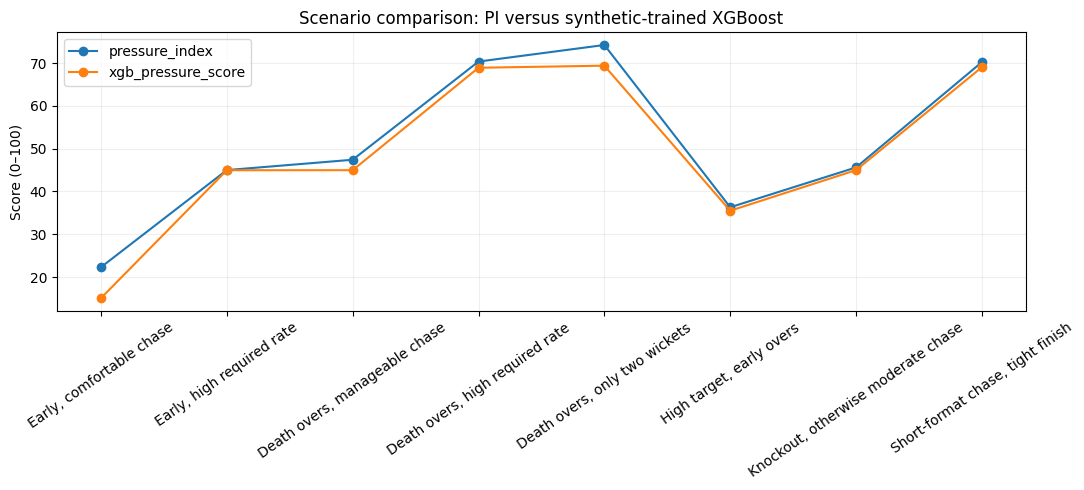

In [10]:
scenario_lab = results["scenario_lab"]
display(scenario_lab[["scenario", "required_run_rate", "wickets_remaining", "balls_remaining", "target_difficulty", "match_stakes", "pressure_index", "xgb_pressure_score", "xgb_pressure_class"]].round(2))
fig, ax = plt.subplots(figsize=(11, 5))
plot_df = scenario_lab.melt(id_vars="scenario", value_vars=["pressure_index", "xgb_pressure_score"], var_name="model", value_name="score")
for model_name, group in plot_df.groupby("model"):
    ax.plot(group["scenario"], group["score"], marker="o", label=model_name)
ax.set_ylabel("Score (0–100)"); ax.set_title("Scenario comparison: PI versus synthetic-trained XGBoost")
ax.tick_params(axis="x", rotation=35); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 8. Player pressure exposure — descriptive only

The player table is a comparison aid. It is not the final tournament ranking. Batters are attributed dismissals using `dismissed_player_id == striker_id`; bowler wickets only include the dismissal types credited to bowlers. Bowler conceded-run estimates can still include unresolved extras.

In [11]:
players = results["players"]
display(players.loc[players["role"].eq("Batter")].sort_values("role_deliveries", ascending=False).head(20))
display(players.loc[players["role"].eq("Bowler")].sort_values("role_deliveries", ascending=False).head(20))

,player_id,player_name,role_deliveries,matches,batter_runs,pi_mean,xgb_mean,high_pi_deliveries,dismissals_of_batter,role,runs_per_100_pressure_deliveries,wickets,provisional_runs_conceded,wickets_per_100_pressure_deliveries,provisional_runs_per_6_deliveries
374,6288,Shubman Gill,1400,58,1941.0,31.242868,27.982124,21,52.0,Batter,138.642857,NaN,NaN,NaN,NaN
88,1699,Suryakumar Yadav,1399,65,2270.0,39.635780,35.020191,52,53.0,Batter,162.258756,NaN,NaN,NaN,NaN
490,7897,Namboori Tilak Varma,1332,62,1774.0,43.293086,38.633546,145,40.0,Batter,133.183183,NaN,NaN,NaN,NaN
249,4117,Ishan Kishan,1161,58,1585.0,32.992807,29.170377,9,53.0,Batter,136.520241,NaN,NaN,NaN,NaN
3,47,Virat Kohli,1127,41,1642.0,32.862551,28.388720,11,31.0,Batter,145.696539,NaN,NaN,NaN,NaN
48,813,Jos Buttler,1126,59,1713.0,32.430690,27.626041,34,50.0,Batter,152.131439,NaN,NaN,NaN,NaN
371,6281,Abhishek Sharma,1079,61,1897.0,30.934803,27.427656,3,58.0,Batter,175.810936,NaN,NaN,NaN,NaN
432,6931,Pathum Nissanka,1060,39,1487.0,30.860492,26.437132,12,34.0,Batter,140.283019,NaN,NaN,NaN,NaN
172,3125,Nicholas Pooran,1038,61,1553.0,42.125132,37.291358,70,47.0,Batter,149.614644,NaN,NaN,NaN,NaN
428,6819,Yashasvi Jaiswal,1032,43,1591.0,29.870487,24.806423,0,37.0,Batter,154.166667,NaN,NaN,NaN,NaN


,player_id,player_name,role_deliveries,matches,batter_runs,pi_mean,xgb_mean,high_pi_deliveries,dismissals_of_batter,role,runs_per_100_pressure_deliveries,wickets,provisional_runs_conceded,wickets_per_100_pressure_deliveries,provisional_runs_per_6_deliveries
1017,6464,Arshdeep Singh,1664,76,NaN,45.238870,41.853442,325,NaN,Bowler,NaN,93.0,2384.0,5.588942,8.596154
1072,7503,Ravi Bishnoi,1439,67,NaN,47.170779,42.114310,247,NaN,Bowler,NaN,77.0,1932.0,5.350938,8.055594
935,4722,Rashid Khan,1406,63,NaN,42.717181,37.493676,182,NaN,Bowler,NaN,88.0,1662.0,6.258890,7.092461
756,360,Bhuvneshwar Kumar,1172,53,NaN,42.458781,39.127104,223,NaN,Bowler,NaN,57.0,1577.0,4.863481,8.073379
791,1612,Yuzvendra Chahal,1161,52,NaN,46.414592,42.128642,185,NaN,Bowler,NaN,77.0,1549.0,6.632214,8.005168
837,2876,Axar Patel,1156,62,NaN,44.420353,40.189380,127,NaN,Bowler,NaN,56.0,1463.0,4.844291,7.593426
1142,19316,Maheesh Theekshana,1141,50,NaN,37.972511,33.049179,123,NaN,Bowler,NaN,42.0,1372.0,3.680982,7.214724
998,6256,Varun Chakravarthy,1113,48,NaN,44.839689,39.898513,197,NaN,Bowler,NaN,77.0,1510.0,6.918239,8.140162
962,4900,Wanindu Hasaranga,1060,49,NaN,38.695317,33.451152,97,NaN,Bowler,NaN,66.0,1502.0,6.226415,8.501887
902,4101,Mitchell Santner,1043,48,NaN,41.222723,35.077500,136,NaN,Bowler,NaN,59.0,1138.0,5.656759,6.546500


## 9. Data quality and interpretation guardrails

- The provided `extras1_runs` values behave as categorical codes. The supplied pack does not clearly contain the numeric run amounts for byes/legbyes.
- The analysis flags 3,166 unresolved bye/legbye deliveries. Provisional innings totals and chase states must be reconciled against official scorecards before final player rankings.
- `stage` and `knock_out` support a match-importance proxy, but no standings/points table is present to calculate whether a team was mathematically required to win.
- XGBoost is trained on synthetic labels only. It is a nonlinear rule-approximation baseline, not a validated pressure model.
- Real PI–XGBoost correlation is agreement between two models, not ground-truth validation.

## 10. Generated artifacts

The pipeline writes:

- `data/synthetic/synthetic_pressure_scenarios.csv`
- `data/synthetic/synthetic_test_predictions.csv`
- `data/processed/real_pressure_comparison.csv.gz`
- `models/synthetic_pressure_xgb.json`
- `outputs/player_pressure_comparison.csv`
- `outputs/match_format_season_summary.csv`
- `outputs/weight_sensitivity.csv`
- `outputs/scenario_lab.csv`
- JSON experiment metrics and PNG diagnostic charts under `outputs/`.

**Next research phase:** reconcile scores, add points tables/qualification rules, then create a separate historical win-probability model with match-grouped and chronological evaluation. That would give us a more independent validation signal.